In [1]:
import pandas as pd
import numpy as np
import os
import sys
from pathlib import Path
import asyncio
from datetime import datetime, timedelta
from plotly import express as px
from sqlalchemy import select

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import joblib

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate

base_dir = Path("__file__").resolve().parents[2]
sys.path.insert(0, str(base_dir))

In [2]:
from data.db.client import init_async_db
from data.db import entities_transformed as et
from data.db.statements import fetch_frame

# Data Transform

In [ ]:
client = init_async_db()

stock_ids = []
start_date = pd.to_datetime(datetime.now() - timedelta(days=90)).normalize()
start_date

Timestamp('2026-07-13 00:00:00')

In [4]:
async with client.begin() as conn:
    stocks_metadata = await fetch_frame(conn, et.StockMetadata, et.StockMetadata.created_at, stock_ids, start_date)
    
    
    models = [
        (et.PriceData, et.PriceData.trade_date),
        # (et.StockMetadata, et.StockMetadata.created_at),
        (et.FundamentalData, et.FundamentalData.created_at),
        (et.DynamicData, et.DynamicData.created_at),
        (et.AnalyticData, et.AnalyticData.created_at),
    ]

    frames = await asyncio.gather(
        *(
            fetch_frame(conn, model, date_col, stock_ids, start_date)
            for model, date_col in models
        )
    )

In [44]:
full_data = pd.DataFrame([])

normalized_data = []
for frame in frames:
    if "created_at" in frame.columns and "trade_date" not in frame.columns:
        frame = frame.rename(columns={"created_at":"trade_date"})

    frame["trade_date"] = pd.to_datetime(frame["trade_date"]).dt.normalize()
    normalized_data.append(frame.copy())


for data in normalized_data:
    if full_data.empty:
        full_data = data.copy()
    else:
        full_data = pd.merge(
            full_data,
            data.copy(),
            on=["stock_id", "trade_date"],
            how="left"
        )

full_data = pd.merge(
    stocks_metadata,
    full_data,
    on="stock_id",
    how="right"
).drop(columns=[c for c in full_data.columns if c.endswith("_y")]).rename(
    columns=lambda c: c[:-2] if c.endswith("_x") else c
).drop(columns=["retrieve_at"])

# full_data = full_data[[
#     "stock_id",
#     "ticker",
#     "trade_date",
#     "close",
#     "free_cashflow",
#     "operating_cashflow",
#     "market_cap"
# ]]

In [45]:
display(full_data.head())

,ceo_name,company_name,created_at,exchange,exchange_timezone_name,full_address,full_time_employees,gmt_offset_hours,industry,market,...,two_hundred_day_average,average_analyst_rating,earnings_end_date,earnings_start_date,is_earnings_date_estimate,number_of_analyst_opinions,recommendation_status,target_high_price,target_low_price,target_mean_price
0,None,None,2026-10-09,JKT,Asia/Jakarta,None,1712.0,None,Rental & Leasing Services,id_market,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,None,None,2026-10-09,JKT,Asia/Jakarta,None,26048.0,None,Farm Products,id_market,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,None,None,2026-08-21,JKT,Asia/Jakarta,None,1552.0,None,Engineering & Construction,id_market,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,None,None,2026-10-09,JKT,Asia/Jakarta,None,561.0,None,Banks - Regional,id_market,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,None,None,2026-10-09,JKT,Asia/Jakarta,None,102.0,None,Specialty Chemicals,id_market,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Momentum**

In [46]:
full_data = full_data.sort_values(by=["stock_id", "ticker", "trade_date"], ascending=True)

In [47]:
full_data["momentum_30d"] = full_data.groupby(["stock_id", "ticker"])["close"].pct_change(30)

/tmp/ipykernel_2092/3794395636.py:1: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  full_data["momentum_30d"] = full_data.groupby(["stock_id", "ticker"])["close"].pct_change(30)


In [48]:
fig = px.line(
    full_data,
    x="trade_date",
    y="momentum_30d",
    color="ticker",
    title="Momentum 30D"
)

fig.show()

## **30d Moving Average**

In [49]:
full_data["moving_avg_30d"] = full_data["close"].rolling(30).mean()

In [50]:
fig = px.line(
    full_data,
    x="trade_date",
    y="moving_avg_30d",
    color="ticker",
    title="Moving Average 30D"
)

fig.show()

## **FCF / Market Cap**

In [51]:
full_data["operating_cashflow"]

5016              NaN
5017              NaN
5018              NaN
5019              NaN
5020              NaN
             ...     
25012             NaN
25013             NaN
25014   -1.796297e+11
25015   -1.796297e+11
25016   -1.796297e+11
Name: operating_cashflow, Length: 29579, dtype: float64

In [52]:
full_data["free_cashflow"]

5016              NaN
5017              NaN
5018              NaN
5019              NaN
5020              NaN
             ...     
25012             NaN
25013             NaN
25014   -3.272944e+11
25015   -3.272944e+11
25016   -3.272944e+11
Name: free_cashflow, Length: 29579, dtype: float64

In [53]:
full_data["market_cap"]

5016              NaN
5017              NaN
5018              NaN
5019              NaN
5020              NaN
             ...     
25012             NaN
25013             NaN
25014    2.037411e+12
25015    2.053841e+12
25016    1.971688e+12
Name: market_cap, Length: 29579, dtype: float64

In [54]:
full_data["fcf_marketcap"] = full_data["free_cashflow"] / full_data["market_cap"]

In [55]:
fig = px.line(
    full_data,
    x="trade_date",
    y="fcf_marketcap",
    color="ticker",
    title="FCF / Market Cap"
)

fig.show()

## **Target Price Deviation**

In [60]:
display(full_data[["target_mean_price"]])

,target_mean_price
5016,NaN
5017,NaN
5018,NaN
5019,NaN
5020,NaN
...,...
25012,NaN
25013,NaN
25014,None
25015,None


In [61]:
full_data[["target_high_price"]]

,target_high_price
5016,NaN
5017,NaN
5018,NaN
5019,NaN
5020,NaN
...,...
25012,NaN
25013,NaN
25014,None
25015,None


In [62]:
full_data[["target_low_price"]]

,target_low_price
5016,NaN
5017,NaN
5018,NaN
5019,NaN
5020,NaN
...,...
25012,NaN
25013,NaN
25014,None
25015,None


## **Recommendation Change**

In [63]:
full_data[["recommendation_status"]]

,recommendation_status
5016,NaN
5017,NaN
5018,NaN
5019,NaN
5020,NaN
...,...
25012,NaN
25013,NaN
25014,None
25015,None


## **Volatility**

In [64]:
# 1. Calculate percentage returns
full_data["returns"] = full_data.groupby(["stock_id", "ticker"])["close"].pct_change()

# 2. Daily volatility over a 30-day rolling window
full_data["volatility_30d_daily"] = full_data["returns"].rolling(window=30).std()

# 3. Annualized volatility over a 30-day rolling window
full_data["volatility_30d_ann"] = full_data["returns"].rolling(window=30).std() * np.sqrt(252)

/tmp/ipykernel_2092/1709307147.py:2: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  full_data["returns"] = full_data.groupby(["stock_id", "ticker"])["close"].pct_change()


In [65]:
fig = px.line(
    full_data,
    x=["ticker", "trade_date"],
    y="volatility_30d_ann",
    color="ticker",
    title="Volatility 30D Annual"
)

fig.show()

# Analytics

## **training**

In [3]:
client = init_async_db()
stock_ids = []

In [4]:
async with client.connect() as app:
    stmt = select(
        et.PriceData.stock_id,
        et.PriceData.trade_date,
        et.PriceData.close,
    ).where(
        et.PriceData.trade_date.between(
            datetime(2021,1,1), datetime(2025,12,31)
        )
    )

    data = await app.execute(stmt)
    data = data.mappings().all()

In [5]:
data = pd.DataFrame(data)
data = data.sort_values(by=["stock_id", "trade_date"], ascending=True)

display(data)

,close,stock_id,trade_date
25649,63.56304168701171875,1,2021-01-04
25650,61.973964691162109375,1,2021-01-05
25651,61.1794281005859375,1,2021-01-06
25652,61.973964691162109375,1,2021-01-07
25653,61.973964691162109375,1,2021-01-08
...,...,...,...
540889,276,472,2025-12-22
540890,276,472,2025-12-23
540891,274,472,2025-12-24
540892,276,472,2025-12-29


In [6]:
# MOMENTUM

# data["momentum_30d"] = data.groupby(["stock_id"])["close"].pct_change(30)

In [7]:
# # 30d MA

# data["moving_avg_30d"] = (
#     data.groupby(["stock_id"])["close"]
#     .rolling(30)
#     .mean()
#     .reset_index(level=0, drop=True)
# )

In [8]:
# # VOLATILITY

# data["returns"] = data.groupby(["stock_id"])["close"].pct_change()
# data["volatility_30d_daily"] = data["returns"].rolling(window=30).std()
# data["volatility_30d_ann"] = data["volatility_30d_daily"] * np.sqrt(252)

In [6]:
data = data.sort_values(["stock_id", "trade_date"])  # adjust date column name
g = data.groupby("stock_id", sort=False)["close"]

data["returns"] = g.pct_change()
data["momentum_30d"] = g.pct_change(30)
data["moving_avg_30d"] = g.rolling(30).mean().reset_index(level=0, drop=True)

data["volatility_30d_daily"] = (
    data.groupby("stock_id", sort=False)["returns"]
        .rolling(30).std()
        .reset_index(level=0, drop=True)
)
data["volatility_30d_ann"] = data["volatility_30d_daily"] * np.sqrt(252)

In [7]:
data["future_close"] = g.shift(-30)
data["forward_return"] = data["future_close"].div(data["close"].astype("int")).sub(1)

In [8]:
data["label"] =  (data["forward_return"] >= 0.05).astype("int8")

In [9]:
data = data.loc[data["forward_return"].notna() & data["label"].notna()].copy()

In [10]:
data[["label"]].value_counts()

label
0        406299
1        148301
Name: count, dtype: int64

In [ ]:
# model = Pipeline(
#     [
#         ("imputer", SimpleImputer(strategy="median")),
#         (
#             "classifier",
#             RandomForestClassifier(
#                 n_estimators=300,
#                 class_weight="balanced",
#                 random_state=42,
#                 n_jobs=None,
#             ),
#         ),
#     ]
# )

In [10]:
# features = data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]].copy()
# label = data[["label"]].copy()

In [ ]:
# model.fit(data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]], data[["label"]])

/home/zakihran/.cache/pypoetry/virtualenvs/idx-portfolio-pipeline-TTZ1zgO7-py3.12/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['momentum_30d','moving_avg_30d','volatility_30d_ann']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_va

In [ ]:
# artifact_dir = Path.joinpath(base_dir, "stock_market/analytics/models/scikit/outperformer_model.joblib")
# artifact_dir

PosixPath('/mnt/c/Users/zakis/OneDrive/Desktop/indonesia-stock-pipeline/stock_market/analytics/models/scikit/outperformer_model.joblib')

In [ ]:
# joblib.dump({"model": model, "features": ["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]}, 
#             artifact_dir)

['/mnt/c/Users/zakis/OneDrive/Desktop/indonesia-stock-pipeline/stock_market/analytics/models/scikit/outperformer_model.joblib']

In [ ]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=None,
            ),
        ),
    ]
)

param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample",
        {0: 1, 1: 2},
        {0: 1, 1: 3},
    ],
}

search = GridSearchCV(
    pipeline,
    param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    ),
    scoring="f1",
    n_jobs=None,
)

search.fit(data[["momentum_30d", "moving_avg_30d", "volatility_30d_an                                          n"]], data["label"])

print(search.best_params_)
print(search.best_score_)

{'classifier__class_weight': {0: 1, 1: 3}, 'classifier__max_depth': None, 'classifier__n_estimators': 200}
0.5580312048941533


In [12]:
artifact_dir = Path.joinpath(base_dir, "stock_market/analytics/models/scikit/outperformer_model_2.joblib")

joblib.dump(
    {
        "model": search,
        "features": ["momentum_30d", "moving_avg_30d", "volatility_30d_ann"],
    },
    artifact_dir,
)

['C:\\Users\\zakis\\OneDrive\\Desktop\\indonesia-stock-pipeline\\stock_market\\analytics\\models\\scikit\\outperformer_model_2.joblib']

## **evaluate**

In [19]:
pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=None,
            ),
        ),
    ]
)

In [12]:
model = joblib.load("./models/scikit/outperformer_model.joblib")["model"]

In [4]:
client = init_async_db()
stock_ids = []

In [13]:
async with client.connect() as app:
    stmt = select(
        et.PriceData.stock_id,
        et.PriceData.trade_date,
        et.PriceData.close,
    ).where(
        et.PriceData.trade_date.between(
            datetime(2020,1,1), datetime(2020,12,31)
        )
    )

    data = await app.execute(stmt)
    data = data.mappings().all()

In [14]:
data = pd.DataFrame(data)
data = data.sort_values(by=["stock_id", "trade_date"], ascending=True)

display(data)

,close,stock_id,trade_date
8562,83.42649078369140625,1,2020-01-02
8563,84.22103118896484375,1,2020-01-03
8564,82.63195037841796875,1,2020-01-06
8565,82.63195037841796875,1,2020-01-07
8566,81.8374176025390625,1,2020-01-08
...,...,...,...
100259,317.809844970703125,472,2020-12-22
100260,323.519012451171875,472,2020-12-23
100261,329.2281494140625,472,2020-12-28
100262,317.809844970703125,472,2020-12-29


In [15]:
data = data.sort_values(["stock_id", "trade_date"])  # adjust date column name
g = data.groupby("stock_id", sort=False)["close"]

data["returns"] = g.pct_change()
data["momentum_30d"] = g.pct_change(30)
data["moving_avg_30d"] = g.rolling(30).mean().reset_index(level=0, drop=True)

data["volatility_30d_daily"] = (
    data.groupby("stock_id", sort=False)["returns"]
        .rolling(30).std()
        .reset_index(level=0, drop=True)
)
data["volatility_30d_ann"] = data["volatility_30d_daily"] * np.sqrt(252)

In [16]:
data["future_close"] = g.shift(-30)
data["forward_return"] = data["future_close"].div(data["close"].astype("int")).sub(1)

In [17]:
data["label"] =  (data["forward_return"] >= 0.05).astype("int8")

In [18]:
data = data.loc[data["forward_return"].notna() & data["label"].notna()].copy()

In [ ]:
# data["label_predict"] = model.predict(data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]])

In [ ]:
# predict_proba = model.predict_proba(data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]])

In [20]:
data["label_predict"] = search.predict(data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]])
predict_proba = search.predict_proba(data[["momentum_30d", "moving_avg_30d", "volatility_30d_ann"]])

In [21]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
)

print("Balanced Accuracy :", balanced_accuracy_score(data["label"], data["label_predict"]))
print("ROC AUC           :", roc_auc_score(data["label"], data["label_predict"]))
print("PR AUC            :", average_precision_score(data["label"], data["label_predict"]))

Balanced Accuracy : 0.48377659288715336
ROC AUC           : 0.48377659288715336
PR AUC            : 0.2937300351283563


In [22]:
print("Accuracy :", accuracy_score(data["label"], data["label_predict"]))
print("Precision:", precision_score(data["label"], data["label_predict"], average='weighted'))
print("Recall   :", recall_score(data["label"], data["label_predict"], average='weighted'))
print("F1 Score :", f1_score(data["label"], data["label_predict"], average='weighted'))

Accuracy : 0.5415134314039015
Precision: 0.5667791961350512
Recall   : 0.5415134314039015
F1 Score : 0.552343172541649


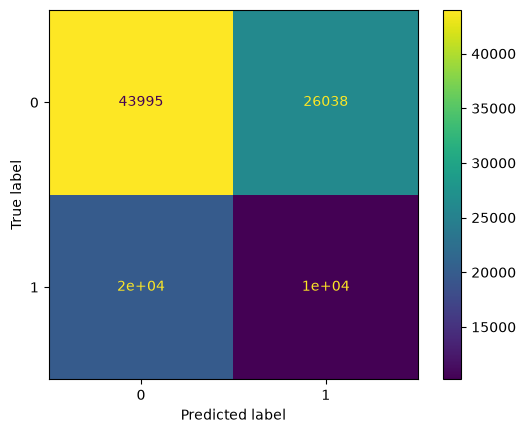

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(data["label"], data["label_predict"])
ConfusionMatrixDisplay(cm).plot()